### Lab 05 – Izhikevich Spiking Neuron Model

In this lab, you will implement the Izhikevich neuron model and simulate different biological firing patterns such as regular spiking, fast spiking, and bursting.

You will complete missing code inside `models/izhikevich.py`.

**Student ID:** MS26910222  
**Name:** N.G. Wickramathilaka  
**Module:** IT5092 – Neuroscience and Neurocomputing (Lab Sheet 5)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from config import DT, T_TOTAL, I_CONST
from config import REGULAR_SPIKING, FAST_SPIKING, BURSTING
from models.izhikevich import simulate_izhikevich
from utils.plotting import plot_trace, plot_multiple_traces
from utils.metrics import firing_rate, isi, spike_count

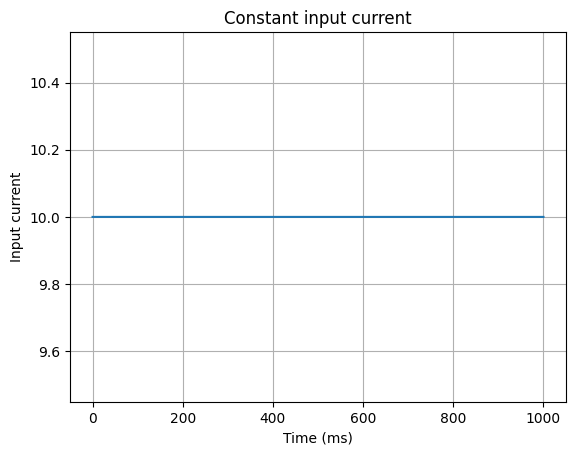

In [2]:
t = np.arange(0, T_TOTAL + DT, DT)
I = np.ones_like(t) * I_CONST

plt.figure()
plt.plot(t, I)
plt.title("Constant input current")
plt.xlabel("Time (ms)")
plt.ylabel("Input current")
plt.grid(True)
plt.show()

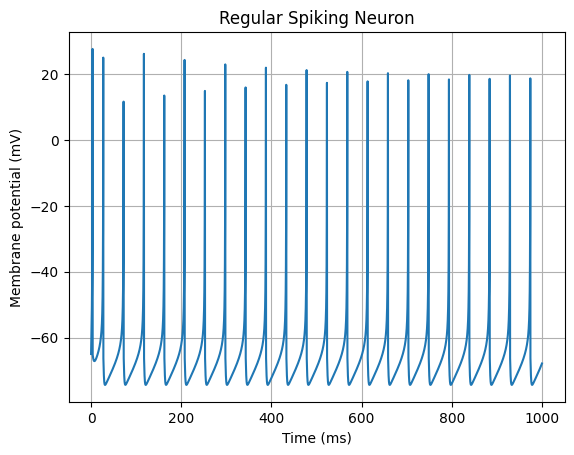

Spike count: 23
Firing rate (Hz): 23.0


In [3]:
# Run regular spiking neuron
params = REGULAR_SPIKING
v_rs, u_rs, sp_rs = simulate_izhikevich(I, t, **params)

plot_trace(t, v_rs, "Regular Spiking Neuron", "Membrane potential (mV)")
print("Spike count:", spike_count(sp_rs))
print("Firing rate (Hz):", firing_rate(sp_rs, 0, T_TOTAL))

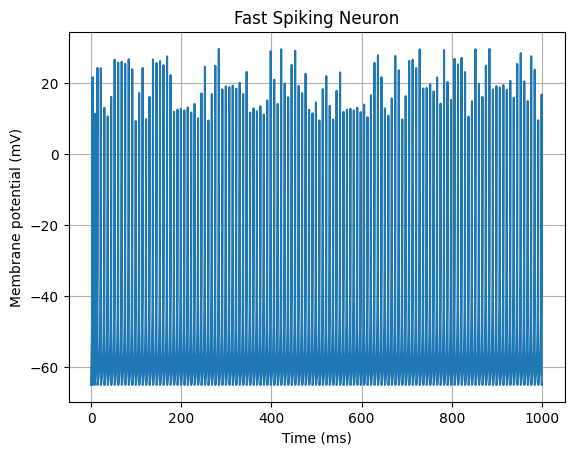

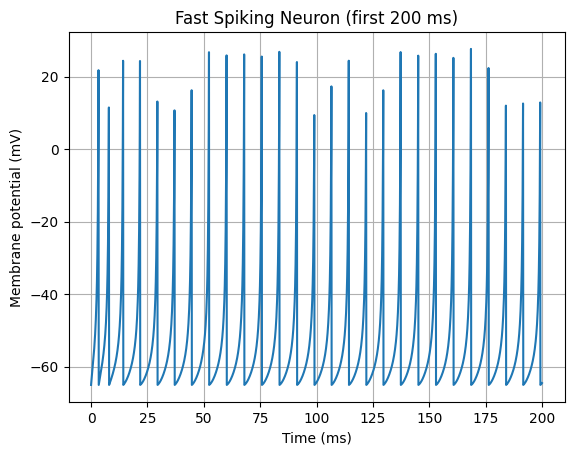

Spike count: 131
Firing rate (Hz): 131.0


In [4]:
# TODO 3:
# Simulate the fast spiking neuron using FAST_SPIKING parameters
params = FAST_SPIKING
v_fs, u_fs, sp_fs = simulate_izhikevich(I, t, **params)

# Plot membrane potential
plot_trace(t, v_fs, "Fast Spiking Neuron", "Membrane potential (mV)")

# Zoomed view of the first 200 ms to see individual spikes clearly
mask = t <= 200
plot_trace(t[mask], v_fs[mask], "Fast Spiking Neuron (first 200 ms)", "Membrane potential (mV)")

# Print spike count and firing rate
print("Spike count:", spike_count(sp_fs))
print("Firing rate (Hz):", firing_rate(sp_fs, 0, T_TOTAL))

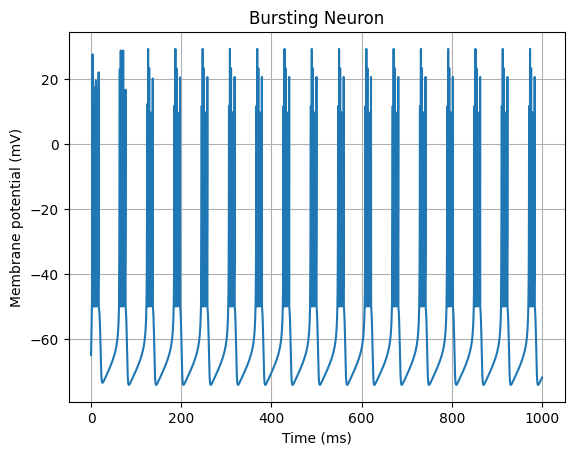

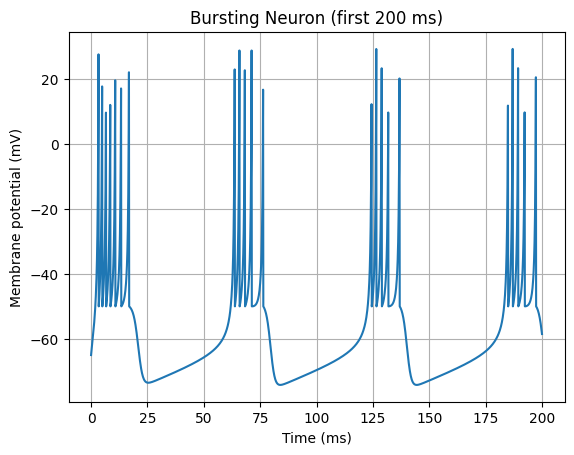

Spike count: 87
Firing rate (Hz): 87.0


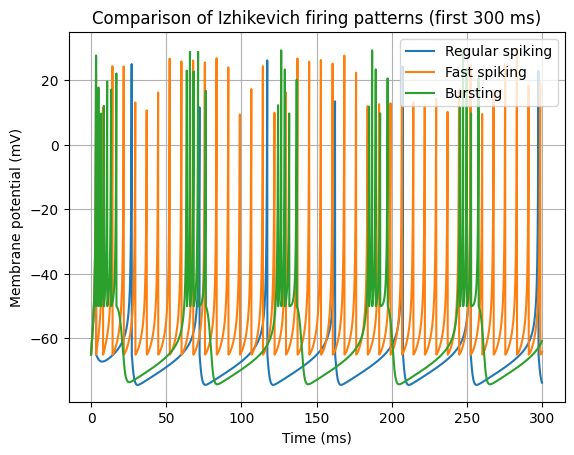

In [5]:
# TODO 4:
# Simulate the bursting neuron using BURSTING parameters
params = BURSTING
v_b, u_b, sp_b = simulate_izhikevich(I, t, **params)

# Plot membrane potential
plot_trace(t, v_b, "Bursting Neuron", "Membrane potential (mV)")

# Zoomed view of the first 200 ms to see the burst structure
mask = t <= 200
plot_trace(t[mask], v_b[mask], "Bursting Neuron (first 200 ms)", "Membrane potential (mV)")

# Print spike count and firing rate
print("Spike count:", spike_count(sp_b))
print("Firing rate (Hz):", firing_rate(sp_b, 0, T_TOTAL))

# Compare all three neuron types on the same axes (first 300 ms)
mask = t <= 300
plot_multiple_traces(t[mask], [v_rs[mask], v_fs[mask], v_b[mask]],
                     ["Regular spiking", "Fast spiking", "Bursting"],
                     "Comparison of Izhikevich firing patterns (first 300 ms)")

Spike times (ms): [  3.4  27.1  72.2 117.3 162.4 207.5 252.6 297.7 342.8 387.9 433.  478.1
 523.2 568.3 613.4 658.5 703.6 748.7 793.8 838.9 884.  929.1 974.2]

Inter-spike intervals (ms): [23.7 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1
 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1]

Number of ISIs : 22
Mean ISI (ms)  : 44.13
Std ISI (ms)   : 4.46
Min / Max ISI  : 23.70 / 45.10 ms
CV of ISI      : 0.101


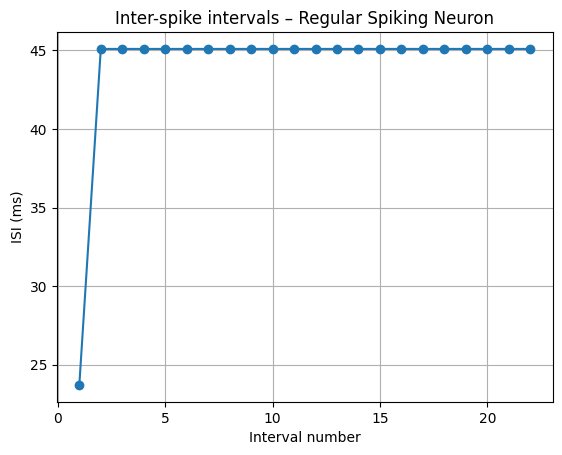

In [6]:
# TODO 5:
# Compute and print inter-spike intervals for the regular spiking neuron
isi_rs = isi(sp_rs)

print("Spike times (ms):", np.round(sp_rs, 1))
print("\nInter-spike intervals (ms):", np.round(isi_rs, 1))
print("\nNumber of ISIs :", len(isi_rs))
print("Mean ISI (ms)  : %.2f" % np.mean(isi_rs))
print("Std ISI (ms)   : %.2f" % np.std(isi_rs))
print("Min / Max ISI  : %.2f / %.2f ms" % (np.min(isi_rs), np.max(isi_rs)))
print("CV of ISI      : %.3f" % (np.std(isi_rs) / np.mean(isi_rs)))

# Plot ISI vs interval number to visualise spike-frequency adaptation
plt.figure()
plt.plot(np.arange(1, len(isi_rs) + 1), isi_rs, marker='o')
plt.xlabel("Interval number")
plt.ylabel("ISI (ms)")
plt.title("Inter-spike intervals – Regular Spiking Neuron")
plt.grid(True)
plt.show()

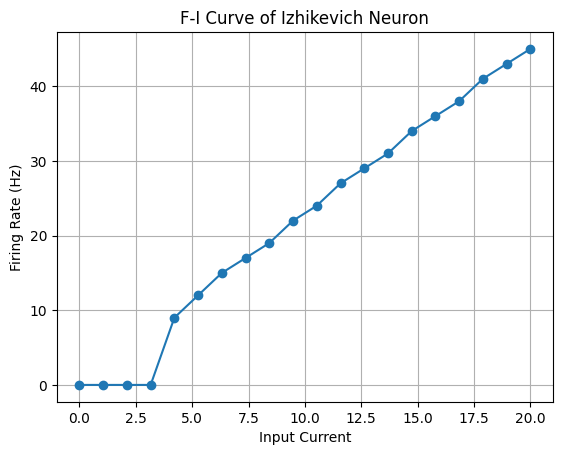

I (input)   Firing rate (Hz)
    0.00       0.0
    1.05       0.0
    2.11       0.0
    3.16       0.0
    4.21       9.0
    5.26      12.0
    6.32      15.0
    7.37      17.0
    8.42      19.0
    9.47      22.0
   10.53      24.0
   11.58      27.0
   12.63      29.0
   13.68      31.0
   14.74      34.0
   15.79      36.0
   16.84      38.0
   17.89      41.0
   18.95      43.0
   20.00      45.0


In [7]:
# TODO 6 – F-I Curve Analysis
# Use the Regular Spiking neuron parameters.
# Vary the input current from:

# 0 → 20

# For each current value:
# simulate the neuron
# compute the firing rate
# store the result
# Plot the F–I curve.
currents = np.linspace(0, 20, 20)
rates = []

for I_value in currents:
    
    # Create input current
    I = np.ones_like(t) * I_value
    
    # Run neuron simulation
    v, u, spikes = simulate_izhikevich(I, t, **REGULAR_SPIKING)
    
    # TODO:
    # compute firing rate using spike_times
    
    rate = firing_rate(spikes, 0, T_TOTAL)
    
    rates.append(rate)

# Plot F-I curve
plt.figure()
plt.plot(currents, rates, marker='o')
plt.xlabel("Input Current")
plt.ylabel("Firing Rate (Hz)")
plt.title("F-I Curve of Izhikevich Neuron")
plt.grid(True)
plt.show()

# Print the F-I table
print("I (input)   Firing rate (Hz)")
for I_value, r in zip(currents, rates):
    print("%8.2f    %6.1f" % (I_value, r))

In [8]:
## TODO 7 – Short Comparison (3–5 sentences)

**Biological realism:** The LIF neuron from Lab 4 is a single linear RC equation (τ = 20 ms) that resets from −50 mV to −65 mV and uses a hand-coded 5 ms refractory rule, whereas the Izhikevich model adds a quadratic voltage term and a recovery variable *u* that builds up after every spike, so it is more biologically realistic. **Number of firing patterns:** Under constant input the LIF neuron can only fire tonically with identical ISIs (8.25 ms every time at amplitude 10 in Lab 4), while the Izhikevich neuron produced three different cortical patterns in this lab just by changing *a, b, c, d* – regular spiking with adaptation (ISI growing from 23.7 ms to 45.1 ms), fast spiking at 131 Hz, and bursting with 4–6 spikes per burst. The F–I curves also differ: the LIF rate rose steeply above its rheobase and then flattened at 180 Hz against its artificial 1000/REFRAC_MS = 200 Hz ceiling, while the Izhikevich regular-spiking rate increased smoothly and almost linearly from 9 Hz to 45 Hz between I ≈ 4 and I = 20 with no hand-coded limit. **Computational cost:** LIF updates one variable per step and Izhikevich updates two with a simple polynomial, so Izhikevich is only slightly more expensive, and both are far cheaper than the Hodgkin–Huxley model from Lab 4, which needed four coupled ODEs with exponential rate functions at dt = 0.01 ms. **When each is useful:** LIF is best for very large networks, analytical work and neuromorphic/SNN learning where only spike timing or rate matters, while Izhikevich is the better choice when a network must reproduce realistic, diverse neuron behaviour such as adaptation or bursting without paying the cost of a conductance-based model.

### Observations

- **Regular spiking (I = 10):** 23 spikes / 23 Hz. The first ISI (23.7 ms) is much shorter than the steady ISI (45.1 ms) because *u* builds up by *d* = 8 after each spike – this is spike-frequency adaptation.
- **Fast spiking (I = 10):** 131 spikes / 131 Hz. The larger *a* (0.1) makes *u* recover quickly and the small *d* (2) gives little adaptation, so the neuron fires at a high, almost constant rate.
- **Bursting (I = 10):** 87 spikes / 87 Hz. The high reset value *c* = −50 mV keeps *v* close to threshold, so several spikes fire rapidly (ISIs ≈ 1.6–5 ms) until *u* accumulates and stops the burst, followed by a long pause (≈ 47 ms).
- **F–I curve:** The neuron is silent for I ≤ 3.16 and starts firing between I ≈ 3.2 and 4.2 (rheobase). Above this, the firing rate increases almost linearly with input current, reaching 45 Hz at I = 20.

*Note:* The spike reset is applied on the time step where *v* crosses 30 mV, so the plotted spike peaks are the last sub-threshold values and appear at slightly different heights (below 30 mV). This does not affect spike times or counts.